# Assignment 2: Exploring sources of bias in data
## Bias in data, demystified

**All datasets have limitations. Any of these limitations can be a potential source of bias.** In the context of data, a "bias" is really just a divergence between what a dataset is supposed to capture about the world--according to the *dataset designer's intention*, or according to the *end-user's expectations*--and what's actually represented in the data. 

So biases in data are often highly *contextual*, which can make them subtle and hard to spot. Similarly, it's hard to predict ahead of time what the *consequences* of those biases might be, because it depends on what the data is being used for.

Nevertheless some sources of "bias" in data show up over and over again. Some of these are:
- **duplicated data:** the same data shows up multiple times
- **incomplete data:** some data is missing from the dataset
- **misleading data:** it looks like a piece of data means one thing, but it actually means something different
- **unrepresentative data:** the dataset doesn't represent the population it's gathered from OR the population it's intended to model


Any of these sources of bias, unless their properly documented (with a data statement, etc) can have unintended consequences: they cause a researcher who is using the data to reach incorrect conclusions, or cause a machine learning model that is trained on that dataset to make classification errors.

The nature or scale of these consequences can be hard to predict. That's why any time you prepare to use data that you didn't gather yourself, it pays to spend some time exploring the dataset, identifying limitations, and thinking critically about how these limitations might affect your analysis or your machine learning model.

## Introduction to Assignment 2
For this assignment, you'll be working with the Wikipedia Talk Corpus. You have already created a data statement for this dataset in class, so you're an 'expert' on it compared to most people!

**In assignment 1, you learned how to process and analyze a dataset created by someone else.** In that assignment, we took the dataset at face value: we assumed that there were no major errors, no missing data, nothing that would skew our results. We assumed that the dataset really did accurately capture all the bike and pedestrian traffic on the Burke-Gilman trail over the specified period of time.

**In assignment 2, we'll also be analyzing a dataset created by someone else,** but this time *we won't assume that the data is complete and correct.* Instead, we will try to identify ways in which the data might be WRONG, and form hypotheses about how the limitations we discover might make it an unsuitable, or at least a potentially problematic, training dataset for a general-purpose hostile speech detector. 

**There are 16 questions in this assignment, across three sections:**

***In part 1 of this assignment,*** you will load one type of Wikipedia Talk Corpus data--the demographics of the crowdworkers who labelled the comments--into your copy of this Jupyter Notebook, and we will walk through a series of data processing steps, with the goal of ending up with a complete and accurate set of data about all of those crowdworkers. In the process, we will discover and discuss several limitations of the dataset.

***In part 2 of this assignment,*** you will generate some basic descriptive statistics about the demographics of the crowdworkers described in that dataset. If you are comfortable in Python, you can perform that analysis in this Notebook. If you aren't as comfortable in Python (yet!), you can perform the analysis in Google Sheets (just be sure to link to that Google Sheet from this notebook, and set the permissions so that your instructors can view it!). 

***In part 3 of this assignment,*** you will answer some additional research questions about this dataset. Some of these questions can be answered without writing additional code or analyzing additional data; other questions will require you to combine this dataset another dataset in the corpus. You will have the option to choose whether you want to answer code or no-code questions.

Whether you choose code or no-code question for part 3, you will need to write your responses to the question within this notebook, and submit a link to this notebook for grading.

Part 3 also contains some optional "challenge" questions that you can investigate if you want to (hint: any one of these challenge questions could be the focus of a final course project).


***Note:*** *Since the purpose of this class is to get you comfortable thinking critically (like a researcher), rather than programming perfectly, you won't be graded on your code. You'll be graded on how well you DOCUMENT YOUR PROCESS and REFLECT on the implications of your findings. If you still aren't sure what that means, ask your instructor or TA!*

## Part 1: Cleaning and analyzing the annotator demographic data

For the first part of this assignment, we're going to prepare one set of Wikipedia Talk data--the annotator demographics files--for analysis. In the process we'll perform a few "sanity checks" to make sure we understand what the data means, and know any limitations.

This sort of "[data wrangling](https://en.wikipedia.org/wiki/Data_wrangling)" is a critical, if sometimes tedious, first step for any quantitative research project.

### 1.1 Load the data into the notebook

According to the documetation, the worker demographic data for the Wikipedia Talk Corpus is spread across three files:
- ``toxicity_worker_demographics.tsv``
- ``aggression_worker_demographics.tsv``
- ``attack_worker_demographics.tsv``

We will need to combine the data in these three files to come up with our canonical list of workers. 
**Just like working with data in the real world, you will need to retrieve the files from their source (Figshare) and transfer them into your notebook server**.

- **Toxicity dataset:** [data](https://figshare.com/articles/dataset/Wikipedia_Talk_Labels_Toxicity/4563973) (Note: this is 35Mb!), [documentation](https://meta.wikimedia.org/wiki/Research:Detox/Data_Release#Toxicity), [questionnaire shown to crowdworkers](https://github.com/ewulczyn/wiki-detox/blob/master/src/modeling/toxicity_question.png)
- **Aggression dataset:** [data](https://figshare.com/articles/dataset/Wikipedia_Talk_Labels_Aggression/4267550) (Note: this is 74Mb!), [documentation](https://meta.wikimedia.org/wiki/Research:Detox/Data_Release#Aggression), [questionnaire shown to crowdworkers](https://github.com/ewulczyn/wiki-detox/blob/master/src/modeling/aggression_question.png)
- **Personal attacks dataset:** [data](https://figshare.com/articles/dataset/Wikipedia_Talk_Labels_Personal_Attacks/4054689) (this is only 92k), [documentation](https://meta.wikimedia.org/wiki/Research:Detox/Data_Release#Personal_Attacksv), [questionnaire shown to crowdworkers](https://github.com/ewulczyn/wiki-detox/blob/master/src/modeling/attack_question.png)

First we'll load each of the annotator datafiles into our Notebook and save them into data structures that's easy to work with. In this case, I'm choosing to save each of these files as a list-of-dictionaries, since that's fairly standard, and it makes it easy to check your work as you go.

By the way: ``.tsv`` stands for "tab-separated values", and it means that this file is organized into rows and columns, like a spreadsheet, and the data values for each column are separated by "tab" characters.

In [1]:
#import the csv module, a little code toolkit for working with spreadsheet-style data files
import csv

The function below will load in a tab-separated (.tsv) file and convert it into a lists-of-dictionaries. 

If you don't have much experience with Python, this (and some of the other code in this notebook) might be hard to understand. That's okay! For now, it's most important that you know what it does.

If you have a ***lot*** of experience with Python, the code in this notebook might seem really, really primitive. That's also okay! Remember: in this course we're primarily interested in data, not code. Code is just one of the many tools we use to ask and answer questions about data.

In [2]:
def prepare_datasets(file_path):
    """ 
    Accepts: path to a tab-separated plaintext file
    Returns: a list containing a dictionary for every row in the file, 
        with the file column headers as keys
    """
    
    with open(file_path) as infile:
        reader = csv.DictReader(infile, delimiter='\t')
        list_of_dicts = [dict(r) for r in reader]
        
    return list_of_dicts

### 1.2 Identifying duplicated datafiles
Let's load our three .tsv files into Python and store them as three variables with relevant names, so that we know which is which. 

Once we've created these three lists-of-dicts, we will do two things to check our work so far: 
- we will print the first annotator's demographic data (list index ``[0]``) so that we know what the format looks like
- we will print the length of each list (the ``len`` function), to see how many rows is in each file. Each row should correspond to one crowdworker/annotator.

***Note:*** for the cell below to run, your version of these datafiles and folders will need have the same names as the ones below, and your version of this Notebook will need to be stored in the same directory as the three folders that hold the datafiles.

In [3]:
#load the data from the flat files into three lists-of-dictionaries
toxicity_annotators = prepare_datasets("wikipedia_datasets/toxicity_worker_demographics.tsv")
print(toxicity_annotators[0])
print(len(toxicity_annotators))

attack_annotators = prepare_datasets("wikipedia_datasets/attack_worker_demographics.tsv")
print(attack_annotators[0])
print(len(attack_annotators))

aggression_annotators = prepare_datasets("wikipedia_datasets/aggression_worker_demographics.tsv")
print(aggression_annotators[0])
print(len(aggression_annotators))



{'worker_id': '85', 'gender': 'female', 'english_first_language': '0', 'age_group': '18-30', 'education': 'bachelors'}
3591
{'worker_id': '833', 'gender': 'female', 'english_first_language': '0', 'age_group': '45-60', 'education': 'bachelors'}
2190
{'worker_id': '833', 'gender': 'female', 'english_first_language': '0', 'age_group': '45-60', 'education': 'bachelors'}
2190


In [27]:
# Evidence check: are the attack and aggression demographic files really identical?
# We compare only the 5 original fields, so this works even if run after section 1.6
# (add_dataset_id later adds extra keys to the attack list's dictionaries).
fields = ['worker_id', 'gender', 'english_first_language', 'age_group', 'education']

def strip_to_fields(rows):
    return [{k: r[k] for k in fields} for r in rows]

attack_clean = strip_to_fields(attack_annotators)
aggression_clean = strip_to_fields(aggression_annotators)

# Row-by-row, same order
print("Same length:", len(attack_clean) == len(aggression_clean))
print("Identical row-by-row:", attack_clean == aggression_clean)

# Order-independent check: same set of workers with the same demographics
as_tuples = lambda rows: {tuple(r[k] for k in fields) for r in rows}
print("Identical as sets:", as_tuples(attack_clean) == as_tuples(aggression_clean))

# What would a naive merge of all three files have looked like?
naive_total = len(toxicity_annotators) + len(attack_annotators) + len(aggression_annotators)
naive_aa_share = (len(attack_annotators) + len(aggression_annotators)) / naive_total
true_total = len(toxicity_annotators) + len(attack_annotators)
true_aa_share = len(attack_annotators) / true_total

print(f"\nNaive merge: {naive_total} rows, attack/aggression workers = {naive_aa_share:.1%} of pool")
print(f"Correct merge: {true_total} rows, attack/aggression workers = {true_aa_share:.1%} of pool")

Same length: True
Identical row-by-row: True
Identical as sets: True

Naive merge: 7971 rows, attack/aggression workers = 54.9% of pool
Correct merge: 5781 rows, attack/aggression workers = 37.9% of pool


**Finding: the attack and aggression demographic files are duplicates.**
A row-by-row comparison shows `attack_worker_demographics.tsv` and `aggression_worker_demographics.tsv` contain identical records (2,190 workers each, same IDs and same demographics). The dataset documentation does not say so.

**What would have gone wrong if I had merged all three files?**
A naive merge would have produced 7,971 rows instead of 5,781, counting 2,190 workers twice. The attack/aggression workers would make up about 55% of the apparent pool instead of their true ~38%, therefore every demographic statistic would be skewed toward that group's makeup. Moreover, I would have reported a crowd of ~8,000 annotators when the dataset actually has ~5,800 rows of annotators, overstating how diverse and how large the labeling workforce was. 

This is the **duplicated data** source of bias. It distorts the population and can make a researcher overconfident in conclusions about it that may be false.

**Decision:** I keep only one of the two files (`attack_aggro_annotators`) and ignore`aggression_annotators` from here on.

Interesting! This tells us a few things that we didn't know before:
1. it looks like the demographic data matches what's listed in [the schema](https://meta.wikimedia.org/wiki/Research:Detox/Data_Release#Schema_for_{attack/aggression/toxicity}_worker_demographics.tsv), which is great!
2. it looks like the "toxicity" dataset was annotated by a lot more people (3,591) than the "attack" or "aggression" datasets (2,190)
3. ``aggression_worker_demographics.tsv`` and ``attack_worker_demographics.tsv`` seem to contain the same number of workers, and the worker at the beginning of each list has the same ID and demographic data.

Let's dig a little deeper into finding #3. Are the ***last*** entries in both of these lists also identical?

In [4]:
print(attack_annotators[-1]) # "-1" tells Python to find the last item in any list
print(aggression_annotators[-1])


{'worker_id': '3876', 'gender': 'female', 'english_first_language': '1', 'age_group': '30-45', 'education': 'bachelors'}
{'worker_id': '3876', 'gender': 'female', 'english_first_language': '1', 'age_group': '30-45', 'education': 'bachelors'}


Yes, the last rows in these two lists are also identical! 

And in fact if you had opened the two lists in a text editor or spreadsheet program, you would find that the *aggression and attack .tsv files contain exactly the same data.* By the way, it doesn't say anywhere in the dataset documentation that these two files are identical!

That brings us to our first lesson about bias: watch out for duplicate data! 

Consider: *What would have happened if we had just combined these three files and then analyzed the worker demographics? What mistaken conclusions might we have drawn from that?*
 
Fortunately, now that we know that there is duplicate data we can work around it. Since two files are identical, we only need to use one of them. So from now on, we will ignore ``aggression_annotators`` entirely. 

Since want to remember that ``attack_annotators`` really refers to both "attack" and "aggression" annotators, we can just rename the variable we're using to store that dataset.

In [5]:
attack_aggro_annotators = attack_annotators

Okay, that looks good. Now we can continue getting our data ready for analysis--while keeping an eye out for additional duplicate data and other "gotchas"!

### 1.3 Understanding what the properties of your data really mean

Whenever you are working with data that you didn't create, it's very useful to perform some basic sanity-checking to make sure the data actually means what you think it means. 

For example, take the ``worker_id`` field in our datasets. 

The [schema](https://meta.wikimedia.org/wiki/Research:Detox/Data_Release#Schema_for_{attack/aggression/toxicity}_worker_demographics.tsv) says that the ``worker_id`` field contains an "anonymized crowd-worker id" and that this ID is meant to join the worker demographics datafiles with the annotator comments datafiles, so that if we wanted find all of the comments that worker "85" (from above) labelled, we could find her by looking for that ID in each row of ``toxicity_annotated_comments.tsv``.

So far, so good. But since we want to combine the toxicity and attack + aggression annotator demographics data into a single dataset, we probably want to know...

1. did any of the values for ``worker_id`` appear in both datasets?
2. if so, do they correspond to the same person (or at least, a person with matching gender, age group, etc.)?

### 1.4 Checking for duplicate worker IDs

If we want to see if worker_id means the same thing across datasets, the first step is to see if any of the same worker_ids exist across the two datasets.

To check this, let's first pull all the worker IDs out of each dataset and combine them into a single list. Then we can check that list to see if it contains any duplicate values. If it does, we know that there is at least 1 value for ``worker_id`` that appears in both datasets.

**Note:** *We're assuming that there are no duplicate values for ``worker_id`` within each dataset. (There aren't, I checked). It's a pretty safe assumption though, because worker_id is intended to be a unique key that links the ``worker_demographics.tsv`` files and the ``annotated_comments.tsv`` datasets. Can you explain why it would be an issue if there were duplicate values for ``worker_id`` within an individual dataset?*

In [6]:
#pull the worker ids out of the individual files
tox_w_ids = [item['worker_id'] for item in toxicity_annotators]
aa_w_ids = [item['worker_id'] for item in attack_aggro_annotators]


#create a new list to hold all the ids
all_w_ids = tox_w_ids + aa_w_ids

# #combine the two worker_id lists into the new list
# all_w_ids.extend(tox_w_ids)
# all_w_ids.extend(aa_w_ids)

In [7]:
#how many worker ids do we have, total? 
#this number should match the total count of toxicity_annotators and attack_aggro_annotators (3591 + 2190 = 5781)
print(len(all_w_ids))

5781


In [8]:
#what does our new list look like? Let's print the first five values
print(all_w_ids[0:5])

['85', '1617', '1394', '311', '1980']


Below is our duplicate-checker function. You pass it a list of values, and it will return "True" if it finds at least 1 duplicate value in that list. Can you figure out how it works?

In [9]:
def determine_dupes(w_ids):
    set_of_ids = set()
    
    found_a_dupe = False
    
    for w in w_ids:
        if w in set_of_ids:
            found_a_dupe = True
        else:
            set_of_ids.add(w)

    return found_a_dupe

In [10]:
#we'll call determine_dupes to check for duplicates in the combined worker id list
has_dupes = determine_dupes(all_w_ids)

#if this prints 'True', that means we found at least one duplicate ID
print(has_dupes)

True


Hmmm... So it looks like there's at least 1 duplicate! Okay, we'll need to do some additional verification before we can decide what to do with that information. 

The next thing we'll do is check how many duplicates there are. We'll write a short script that reads through ``all_w_ids`` and every time it finds a value that appears more than once, it adds that value to a new list.

Can you figure out how the script below works?

In [11]:
#create an empty list to hold any duplicate worker_id values we find
dupes = []

#look through the data, if you encounter any value more than once, add it to our 'dupes' list
for w in all_w_ids:
    if all_w_ids.count(w) > 1:
        dupes.append(w)

#how many values were added to 'dupes'?        
print(len(dupes))

#how many worker_ids are present twice in the dataset?
#can you explain why we are dividing the length of "dupes" by 2 in order to answer that question?
print(len(dupes)/2)

3716
1858.0


In [28]:
# Evidence check for the 1.4 claims, rather than taking "I checked" on trust.

tox_ids = [w['worker_id'] for w in toxicity_annotators]
aa_ids = [w['worker_id'] for w in attack_aggro_annotators]

# 1) Are worker_ids unique WITHIN each file? (rows vs. distinct ids)
print("Toxicity:               rows =", len(tox_ids), "| distinct ids =", len(set(tox_ids)))
print("Attack/aggression:      rows =", len(aa_ids),  "| distinct ids =", len(set(aa_ids)))

# 2) How many ids appear in BOTH files? (set intersection, independent of the dupes loop)
shared_ids = set(tox_ids) & set(aa_ids)
print("\nIds appearing in both files:", len(shared_ids))
print(f"  = {len(shared_ids) / len(set(aa_ids)):.1%} of attack/aggression ids")
print(f"  = {len(shared_ids) / len(set(tox_ids)):.1%} of toxicity ids")

# 3) Cross-check against the earlier 'dupes' loop
print("\nMatches earlier dupes/2 result:", len(shared_ids) == len(dupes) / 2)

Toxicity:               rows = 3591 | distinct ids = 3591
Attack/aggression:      rows = 2190 | distinct ids = 2190

Ids appearing in both files: 1858
  = 84.8% of attack/aggression ids
  = 51.7% of toxicity ids

Matches earlier dupes/2 result: True


### 1.4 findings: worker_id is not a unique identifier across files

**Within each file, worker_id is unique.** Row counts equal distinct-ID counts in bothfiles (3,591 and 2,190), therefore each file is internally consistent.

**Across files, it is not.** 1,858 worker_ids appear in both the toxicity file and the attack/aggression file. That is ~85% of the attack/aggression IDs and ~52% of the toxicity IDs. However, note that an ID's presence in two files does not mean the same person. The IDs may simply have been numbered separately for each labeling project, which would produce heavy overlap by construction (I test this in 1.5).

**Why duplicate IDs within a single file would be a problem.** `worker_id` is the join key that links demographics to the annotation files. If one ID appeared twice with different demographics, a join would become ambiguous. Either each of that worker's annotations gets duplicated (inflating counts of comments and labels), or it gets the wrong demographic profile. Either way, any later claim like "X% of comments were labeled by women" would be wrong. It would also double-count that worker in every demographic table.

**Why `len(dupes) / 2` gives the number of repeated IDs.** The loop appends an ID to `dupes` every time it appears with a count above 1. Each shared ID appears exactly twice in the combined list (once per file), so each one is appended twice. Dividing by 2 converts "appended values" into "distinct IDs". This only works because IDs are unique within each file (verified above). An ID appearing three times would break the shortcut. The set-intersection result (1,858) independently confirms the number.

Huh, so it looks like 1,858 of the ``worker_ids`` in our merged dataset are duplicates! That's a lot of duplication, since our list was only 5,781 rows in the first place, including these dupes! 

We will definitely need to account for these duplicates before we start analyzing worker demographics. 
- If the duplicate ``worker_id``s have different demographic metadata, we will assume they are different people with the same ID. 
- If the metadata is identical, then we know we can safely remove the duplicates
- If some metadata is identical and some is different... well, let's hope that's not the case!

### 1.5 Check for duplicate worker demographic metadata
Let's see if it's just the value for ``worker_id`` that is duplicated across the two datasets (meaning that the these duplicate ids correspond to different workers with different demographics), or if ``worker_id`` really corresponds to the same people across ``toxicity_annotators`` and ``attack_annotators``.

To do this we'll perform some spot checks, meaning we'll visually compare the demographic data of workers with duplicate IDs, to see if they look like the same worker, or not. Running random 'spot checks' is a really common and useful way of finding systematic issues with your data without having to check every entry. 
 

First, we'll extract 10 random ids from our dupe set. Using a random sample (rather than just looking at the first 10 rows, for instance) helps us be more confident that any patterns we see are really there.

In [12]:
#handy Python library that lets you select things randomly from a list
import random

In [13]:
#convert our 'dupes' list into a set
#bonus: can you explain why we created "dupeset" rather than just grabbing 10 random values from "dupes"?
#hint: in Python, a 'set' is like a list that can only contain a single instance of any value
dupeset = sorted(set(dupes))

#store our random sample of dupes in its own list
dupe_sample = random.sample(dupeset, 10)

#print to confirm everything looks how we expect it to...
print(dupe_sample)

['3543', '1780', '1415', '1600', '3454', '30', '3036', '855', '1381', '3964']


In [29]:
# Stronger test of "shared worker_ids are different people":
# compare ALL shared ids (not just 10), and compare against a chance baseline.
from collections import Counter

fields = ['gender', 'english_first_language', 'age_group', 'education']

tox_by_id = {w['worker_id']: w for w in toxicity_annotators}
aa_by_id = {w['worker_id']: w for w in attack_aggro_annotators}
shared_ids = sorted(set(tox_by_id) & set(aa_by_id))
n = len(shared_ids)

# 1) Observed: for each field, how often do the two records for a shared id agree?
observed = {}
for f in fields:
    observed[f] = sum(tox_by_id[i][f] == aa_by_id[i][f] for i in shared_ids) / n

# 2) Chance baseline: if the two records were two unrelated people, how often would
#    a field agree anyway? = sum over values of P(value in tox file) * P(value in attack file)
def chance_match(field):
    ct = Counter(w[field] for w in toxicity_annotators)
    ca = Counter(w[field] for w in attack_aggro_annotators)
    nt, na = sum(ct.values()), sum(ca.values())
    return sum((ct[v] / nt) * (ca[v] / na) for v in ct if v in ca)

print(f"Shared ids compared: {n}\n")
print(f"{'field':<26}{'observed match':>16}{'chance match':>16}")
chance = {}
for f in fields:
    chance[f] = chance_match(f)
    print(f"{f:<26}{observed[f]:>16.1%}{chance[f]:>16.1%}")

# 3) How many of the 4 fields agree per id? (0-4)
fields_agreeing = Counter(
    sum(tox_by_id[i][f] == aa_by_id[i][f] for f in fields) for i in shared_ids
)
print("\nNumber of matching fields per shared id:")
for k in range(5):
    print(f"  {k} of 4 fields match: {fields_agreeing[k]:>5} ids ({fields_agreeing[k] / n:.1%})")

# 4) Expected number of ids matching on ALL 4 fields by chance alone
#    (approximation: treats fields as independent)
p_all = 1.0
for f in fields:
    p_all *= chance[f]
print(f"\nIds matching on all 4 fields: observed = {fields_agreeing[4]}, "
      f"expected by chance ≈ {p_all * n:.0f}")

Shared ids compared: 1858

field                       observed match    chance match
gender                               53.8%           53.4%
english_first_language               70.5%           69.9%
age_group                            39.1%           38.9%
education                            25.9%           28.1%

Number of matching fields per shared id:
  0 of 4 fields match:   121 ids (6.5%)
  1 of 4 fields match:   512 ids (27.6%)
  2 of 4 fields match:   746 ids (40.2%)
  3 of 4 fields match:   403 ids (21.7%)
  4 of 4 fields match:    76 ids (4.1%)

Ids matching on all 4 fields: observed = 76, expected by chance ≈ 76


### 1.5 findings: are shared worker_ids the same people?

**The notebook's spot check is weak evidence.** It compares 10 randomly sampled ids by eye. That's a useful first look, but 10 of 1,858 shared ids is 0.5% of the overlap, and "few if any look the same" is a judgment call. I tested all 1,858.

**Method.** For every shared id, I compared the four demographic fields across the two files. To interpret the match rates, I computed a chance baseline: the agreement rate you'd expect if the two records were two unrelated people drawn from each file's demographic mix.

**Results.** 
[ Field | Observed match | Chance match |
|---|---|---|
| gender | 53.8% | 53.4% |
| english_first_language | 70.5% | 69.9% |
| age_group | 39.1% | 38.9% |
| education | 25.9% | 28.1% |

Only 76 of 1,858 shared ids (4.1%) matched on all four fields, versus ≈76 expected by chance. Most ids matched on 1 to 3 fields (27.6%, 40.2%, and 21.7%), and 121 (6.5%) matched on none.

**Conclusion.** Agreement across files is essentially what chance alone predicts. Three fields are within about one percentage point of their baselines, and the count of fully matching ids (76) equals the chance expectation. If a meaningful share of shared ids belonged to the same person, observed agreement would sit clearly *above* chance, since a true repeat would match on stable traits like gender and first language. It doesn't. Education is slightly *below* chance (25.9% vs 28.1%); with 1,858 comparisons that gap is small and I don't read anything into it beyond noting it. Together, the evidence indicates that a shared `worker_id` is just a coincidence of numbering: the two files appear to have numbered their workers separately, so the same integer was reused for different people.

**Assumption, stated explicitly.** This supports, but does not prove, that the files used different people. Two caveats: (1) a worker who appears in both projects could have been assigned different ids, and the data gives no way to detect that; (2) a person's self-reported demographics can change between surveys (an "Under 18" respondent who ages, or a changed education level), so some true repeats could look like mismatches. Because the demographic survey was optional and self-reported, I can only say the data are *consistent with* distinct workers.

**Decision.** Treat the two files as separate worker pools, and give every row a new `unique_id` in 1.6 so that `worker_id` is never used alone as a key.

**Bonus: why `dupeset = sorted(set(dupes))`?** `dupes` contains every shared id twice (once per file). `random.sample` draws positions, not distinct values, so sampling straight from `dupes` could return the same id twice and leave me with fewer than 10 distinct workers to check. Converting to a set removes the repeats; `sorted()` turns it back into a list that `random.sample` accepts (newer Python versions no longer allow sampling directly from a set) and keeps the pool in a stable order.

Now, we'll use this ``dupe_sample`` list that we created to pull the corresponding worker demographics from each of our two datasets, using the function below. See if you can figure out how the function works!

In [14]:
def worker_id_lookup(annotator_list, dupe_id):
    """
    Accepts: a list of dictionaries 
        & a list of known duplicate values for
        the key 'worker_id' in those dictionaries
    
    If a duplicate value for worker_id is found, 
        print the complete dictionary of demographic data for that worker
    
    """
    
    for a in annotator_list:
        if a['worker_id'] == dupe_id:
            print(a)
            
#loop through the duplicate sample list and call our worker_id_lookup function
#to check each dataset for corresponding worker demographic data
for d in dupe_sample:
    worker_id_lookup(toxicity_annotators, d)
    worker_id_lookup(attack_aggro_annotators, d)

{'worker_id': '3543', 'gender': 'female', 'english_first_language': '1', 'age_group': '18-30', 'education': 'hs'}
{'worker_id': '3543', 'gender': 'male', 'english_first_language': '0', 'age_group': '18-30', 'education': 'bachelors'}
{'worker_id': '1780', 'gender': 'male', 'english_first_language': '0', 'age_group': '18-30', 'education': 'bachelors'}
{'worker_id': '1780', 'gender': 'female', 'english_first_language': '0', 'age_group': '18-30', 'education': 'bachelors'}
{'worker_id': '1415', 'gender': 'female', 'english_first_language': '0', 'age_group': '45-60', 'education': 'masters'}
{'worker_id': '1415', 'gender': 'male', 'english_first_language': '0', 'age_group': '30-45', 'education': 'bachelors'}
{'worker_id': '1600', 'gender': 'female', 'english_first_language': '0', 'age_group': '30-45', 'education': 'professional'}
{'worker_id': '1600', 'gender': 'male', 'english_first_language': '0', 'age_group': '45-60', 'education': 'bachelors'}
{'worker_id': '3454', 'gender': 'male', 'engli

Aha! It looks like few if any of these ``worker_id`` values correspond to the same demographic data info across the two datasets. 

It's possible that some of the same people labelled both datasets and were assigned different IDs each time. But there's no way for us to determine that with the data we have. 

So for now we will assume that these datasets were labelled by two entirely different sets of crowdworkers. Which means we can combine these two datasets into one, with no duplication to mess up our analysis.

### 1.6 Final preparation of the dataset

Before we start our analysis of worker demographics, let's do two more things:

1. Since we know now that worker ID isn't unique, let's give each worker in our new, combined dataset a **truly** unique ID.
2. While we're at it, let's also add a new field to each worker's demographic dictionary that lists which dataset the worker worked on (toxicity or attack/aggressive).

In [15]:
def add_dataset_id(list_of_dicts, dataset_ref):
    """
    Accepts: a list of dictionaries & a strig value for "dataset"
    Returns: that list of dictionaries, with the new "dataset" key and the specified value
    """
        
    for w in list_of_dicts:
        w.update({"dataset" : dataset_ref})
        
    return list_of_dicts

In [16]:
#update our worker demographic datasets with the new key and value
toxicity_annotators = add_dataset_id(toxicity_annotators, "toxicity")
attack_aggro_annotators = add_dataset_id(attack_aggro_annotators, "attack and aggression")

In [17]:
#did it work?
print(toxicity_annotators[0])
print(attack_aggro_annotators[0])

{'worker_id': '85', 'gender': 'female', 'english_first_language': '0', 'age_group': '18-30', 'education': 'bachelors', 'dataset': 'toxicity'}
{'worker_id': '833', 'gender': 'female', 'english_first_language': '0', 'age_group': '45-60', 'education': 'bachelors', 'dataset': 'attack and aggression'}


Great. Now we'll use the function below to... 

1. combine the two datasets into one
2. assign a truly unique id to each worker 

It doesn't matter what this ID is, as long as its unique within the dataset. We'll use sequential IDs, starting at "1" and going up from there.

In [18]:
def finalize_dataset(list1, list2):
    
    #combine the two lists into a new one
    combined_list = list1 + list2
    
    #initialize our counter variable
    new_id = 1
    
    for w in combined_list:
        #add the new sequential id field, and populate with the current value of 'counter'
        w.update({"unique_id" : str(new_id)})
        
        #increment the counter variable by 1, so that the next ID will be one number higher
        new_id = new_id + 1
        
    return combined_list

In [19]:
#create our new combined list with sequential IDs
all_annotators = finalize_dataset(toxicity_annotators, attack_aggro_annotators)

#print the list length and a sample, for sanity-checking purposes
print(len(all_annotators))
print(all_annotators[0])

5781
{'worker_id': '85', 'gender': 'female', 'english_first_language': '0', 'age_group': '18-30', 'education': 'bachelors', 'dataset': 'toxicity', 'unique_id': '1'}


In [30]:
import pandas as pd

# 1) Is unique_id actually unique? Is worker_id still NOT unique in the combined data?
uids = [w['unique_id'] for w in all_annotators]
wids = [w['worker_id'] for w in all_annotators]
print("Rows:", len(all_annotators))
print("Distinct unique_id:", len(set(uids)), "| all unique:", len(set(uids)) == len(uids))
print("Distinct worker_id:", len(set(wids)), "(worker_id alone is NOT a safe key)")
print("Expected distinct worker_ids: 3591 + 2190 - 1858 =", 3591 + 2190 - 1858)

# 2) Does every row have the same set of fields?
key_sets = {tuple(sorted(w.keys())) for w in all_annotators}
print("\nDistinct key layouts across rows:", len(key_sets))

# 3) Convert to a DataFrame for analysis from here on
df = pd.DataFrame(all_annotators)
print("\nRows per source dataset:")
print(df['dataset'].value_counts())
print("\nColumns:", list(df.columns))
df.head()

Rows: 5781
Distinct unique_id: 5781 | all unique: True
Distinct worker_id: 3923 (worker_id alone is NOT a safe key)
Expected distinct worker_ids: 3591 + 2190 - 1858 = 3923

Distinct key layouts across rows: 1

Rows per source dataset:
dataset
toxicity                 3591
attack and aggression    2190
Name: count, dtype: int64

Columns: ['worker_id', 'gender', 'english_first_language', 'age_group', 'education', 'dataset', 'unique_id']


,worker_id,gender,english_first_language,age_group,education,dataset,unique_id
0,85,female,0,18-30,bachelors,toxicity,1
1,1617,female,0,45-60,bachelors,toxicity,2
2,1394,female,0,,bachelors,toxicity,3
3,311,male,0,30-45,bachelors,toxicity,4
4,1980,male,0,45-60,masters,toxicity,5


### 1.6 summary: the analysis-ready dataset

**What I built.** One table of 5,781 rows, one per worker-record: 3,591 from the toxicity file and 2,190 from the attack/aggression file (the aggression file was dropped as an exact duplicate of the attack file, see 1.2). Each row has `worker_id`, four demographic fields, a `dataset` label, and a new `unique_id`.

**Verification.** `unique_id` is unique across all 5,781 rows. `worker_id` is not: the table has only 3,923 distinct values because 1,858 ids appear in both source files (see 1.4). Any join or count that uses `worker_id` alone, without the `dataset` label, would merge different people. I therefore treat (`worker_id`, `dataset`) as the natural key, or `unique_id` for analysis.

**Important caveat on what a "row" means.** 5,781 rows are *worker-records*, not verified distinct humans. Section 1.5 found no evidence that the two files share workers, but the data cannot rule out a person who labeled for both projects under two different ids. So 5,781 is best read as an upper bound on the number of distinct workers.

**Remaining data-quality work.** I have not yet handled blank survey answers (the demographic survey was optional) or checked for unexpected values such as "Under 18". Those are examined in Q4 and Q5 below, and I deliberately leave the blanks in place until then so that I can measure them rather than silently drop them.

It worked! Now we can FINALLY start to analyze this dataset, and find out more about the workers who labelled the Wikipedia Talk Corpus.

## Part 2: Analyzing worker demographics

Now that we have our worker demographic data de-duplicated, combined and uniquely identified, we can start using it to ask and answer research questions! 

You are welcome to do this next steps in Python, here in this notebook. But if you aren't super comfortable with Python, you can run the cell below to export this dataset to a .csv file called ``a2_all_annotator_demographics.csv`` which you can open in Google Sheets and do the analysis there.

Note: if you choose Google Sheets, please title your Google Sheet "A2 worker demographics", share it with your instructor and TA ("can view" or "can edit") and paste a link to it in a Markdown cell below.

In [20]:
with open('a2_all_annotator_demographics.csv', 'w', encoding='utf-8') as f:
    writer = csv.writer(f)
    #write a header row
    writer.writerow(('unique_id',
                     'worker_id', 
                     'gender', 
                     'english_first_language', 
                     'age_group',
                     'education',
                     'dataset',))
    #loop through our dataset and write it to the file, row by row
    for a in all_annotators:
        writer.writerow((a['unique_id'], a['worker_id'], a['gender'], a['english_first_language'], a['age_group'], a['education'], a['dataset']))

### 2.1 Questions 1-4: compute descriptive statistics

Please create tables or bar charts that answer the following questions:

- **Q1.** What is the gender distribution of these workers?
- **Q2.** What is the distribution of the workers by first language?
- **Q3.** What is the distribution of these workers by age group?
- **Q4.** what is the distribution of these workers by education level?

If you *do not know* how to create tables in Python, you can use Excel or another tool and upload it to your notebook server. However I would encourage you to try out the [Pandas](https://pandas.pydata.org/pandas-docs/version/0.15/10min.html) library, which makes it very easy to convert your data into tidy tabular representations. If you do not know how to create charts in Python, you can use an easy library such as [Plotly](https://plotly.com/python/v3/statistics-charts/#new-to-plotly) to create charts.

**POST YOUR ANSWERS TO QUESTIONS 1-4 HERE.**

Use both Markdown and code-formatted cells.

Q1. Gender distribution (n = 5781)
        count  percent
gender                
female   2103     36.4
male     3676     63.6
other       2      0.0 



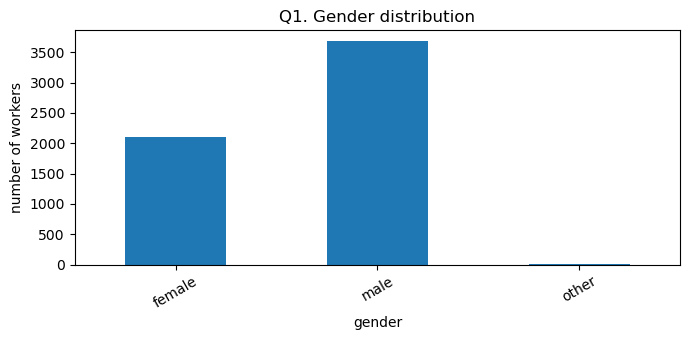

Q2. First-language distribution (n = 5781)
                            count  percent
english_first_language                    
English first language       1068     18.5
English NOT first language   4713     81.5 



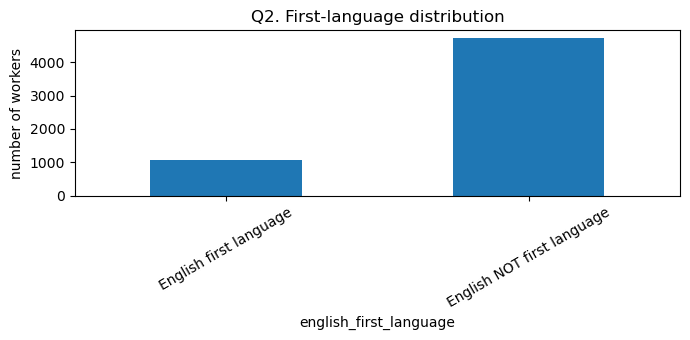

Q3. Age-group distribution (n = 5781)
           count  percent
age_group                
Under 18     116      2.0
18-30       2911     50.4
30-45       2078     35.9
45-60        514      8.9
Over 60       50      0.9
(blank)      112      1.9 



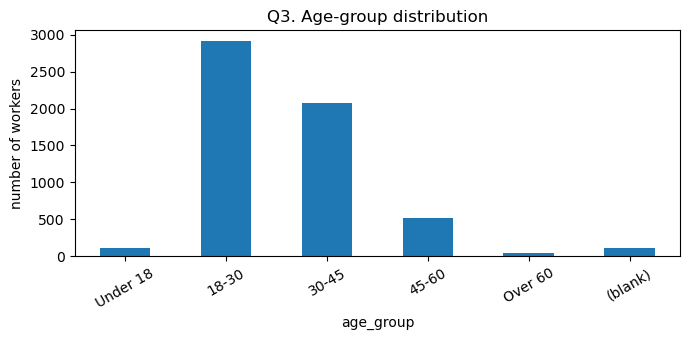

Q4. Education-level distribution (n = 5781)
              count  percent
education                   
none              4      0.1
some            141      2.4
hs             1657     28.7
bachelors      2303     39.8
masters         931     16.1
doctorate        61      1.1
professional    684     11.8 



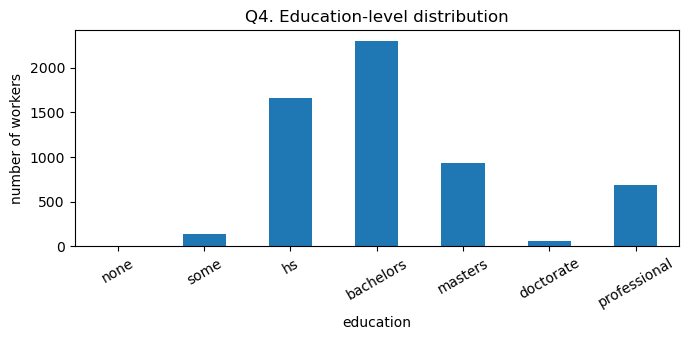


gender by source dataset (% within dataset)
gender                 female  male  other
dataset                                   
attack and aggression    38.4  61.6    0.0
toxicity                 35.2  64.8    0.0

english_first_language by source dataset (% within dataset)
english_first_language     0     1
dataset                           
attack and aggression   81.6  18.4
toxicity                81.5  18.5

age_group by source dataset (% within dataset)
age_group              (blank)  18-30  30-45  45-60  Over 60  Under 18
dataset                                                               
attack and aggression      1.6   47.9   37.9   10.0      0.9       1.7
toxicity                   2.1   51.9   34.7    8.2      0.8       2.2

education by source dataset (% within dataset)
education              bachelors  doctorate    hs  masters  none  \
dataset                                                            
attack and aggression       39.4        0.9  28.8     17.6   0.0  

In [31]:
#[Here's a starter code cell for Q1-Q4]

import matplotlib.pyplot as plt

# Logical category order for each field (from the data statement's schema)
order = {
    'gender': ['female', 'male', 'other'],
    'english_first_language': ['1', '0'],
    'age_group': ['Under 18', '18-30', '30-45', '45-60', 'Over 60'],
    'education': ['none', 'some', 'hs', 'bachelors', 'masters', 'doctorate', 'professional'],
}
# Readable labels for the 0/1 field
pretty = {'english_first_language': {'1': 'English first language', '0': 'English NOT first language'}}

def distribution(col):
    """Count and percent of workers per category, keeping blanks visible."""
    s = df[col].replace('', '(blank)')
    counts = s.value_counts()
    # expected categories first (even if zero), then anything unexpected, e.g. '(blank)'
    idx = order[col] + [v for v in counts.index if v not in order[col]]
    counts = counts.reindex(idx, fill_value=0)
    table = pd.DataFrame({'count': counts, 'percent': (counts / counts.sum() * 100).round(1)})
    table.index = [pretty.get(col, {}).get(v, v) for v in table.index]
    table.index.name = col
    return table

titles = {
    'gender': 'Q1. Gender distribution',
    'english_first_language': 'Q2. First-language distribution',
    'age_group': 'Q3. Age-group distribution',
    'education': 'Q4. Education-level distribution',
}

for col in order:
    t = distribution(col)
    print(titles[col], f"(n = {len(df)})")
    print(t, "\n")
    ax = t['count'].plot(kind='bar', title=titles[col], rot=30, figsize=(7, 3.5))
    ax.set_ylabel('number of workers')
    plt.tight_layout()
    plt.show()

# Extra: do the two source pools look alike? (row percentages within each dataset)
for col in order:
    s = df[col].replace('', '(blank)')
    print(f"\n{col} by source dataset (% within dataset)")
    print((pd.crosstab(df['dataset'], s, normalize='index') * 100).round(1))

### Q1-Q4: Who labeled the data?

*All figures are percentages of 5,781 worker-records (3,591 toxicity + 2,190 attack/aggression), with blanks kept visible rather than dropped.*

**Q1. Gender.** 63.6% male (3,676), 36.4% female (2,103), and 2 workers (<0.1%) who chose "other." There are about 1.75 male workers for every female worker, and the "other" category is too small to say anything about.

**Q2. First language.** 81.5% of workers (4,713) say English is *not* their first language. Only 18.5% (1,068) say it is. This is the most striking result: the people deciding what counts as hostile English-language Wikipedia comments are overwhelmingly not native English speakers. (Caveat: "English as a first language" is self-reported and is not a measure of proficiency. Many of these workers may be highly fluent.)

**Q3. Age.** The pool is young. 50.4% are 18-30 and 35.9% are 30-45, so 86.3% are under 45. Only 9.8% are over 45 (8.9% 45-60, 0.9% over 60). Also, 116 workers (2.0%) report being **under 18**, and 112 (1.9%) left age blank.

**Q4. Education.** 68.8% hold at least a bachelor's degree (bachelors 39.8%, masters 16.1%, professional 11.8%, doctorate 1.1%). 31.2% have a high-school education or less (hs 28.7%, some schooling 2.4%, none 0.1%).

**Do the two source datasets differ?** Only slightly. The largest gaps between the toxicity pool and the attack/aggression pool are about 4 points (age 18-30: 51.9% vs 47.9%; female: 35.2% vs 38.4%). Pooling them does not hide a major difference.

**What this suggests (hypotheses, not conclusions).** The labels reflect the judgments of a pool that is mostly male, young, college-educated, and mostly non-native English speakers. None of these facts makes any individual label wrong. But "toxic" is a judgment that depends on norms, idiom, tone, and sarcasm, and this pool may not share those with the people Perspective API is meant to serve. One way this could matter: workers reading English as a second language may rate idiomatic or sarcastic comments differently from native speakers. I do not yet know in which direction, and I test related questions in Q9-Q11. Q7 compares this pool to an outside benchmark (English-speaking internet users).

**Limits of this analysis.** These numbers come from an optional, self-reported survey, so they describe survey respondents. The data has no location, language proficiency, or work-history fields, so I cannot say, for example, which countries these workers are in.

### 2.2 Questions 5-8

Each of the next four questions requires a different kinds of answer.

Questions 5 and 6 have a "correct" answer, but we'll still give you credit for the "incorrect" answer as long as you document your process well (in Markdown, in this notebook). These questions are intended to get you thinking about how even small errors in data processing can create bias in your data.

Question 6 requires you to re-run some (but not all) of the data processing steps you performed above. Do this by copying the code into NEW cells below this line, and make sure to document each step using Markdown cells or inline (#) comments. You will probably want to change the names of the variables too.

- **Q5.** Analyze all_annotators in Sheets or Jupyter: Do any of the fields in this dataset have missing data? If so, which fields, and what % of the rows contain missing values?
- **Q6.** Build a version of the all_annotators dataset *without removing duplicates*, then re-run the summary statistics from questions 1-4. How have these summary statistics changed?

Questions 7 and 8 don't have one "correct" answer. These questions are intended to get you thinking about how using this dataset to train a machine learning model might lead to bias in the way that model performs when used as intended. You will need to provide a written answer to each of these questions in 3-4 full sentences. Consider what you know about the workers themselves, the task they were given, and about the purpose of the Perspective API.

Question 7 requires you to do some research of your own (hint: use Google). Question 8 doesn't require any new analysis or research, just critical thinking.

- **Q7.** In general, how do the demographics of these workers compare to those of English-speaking internet users overall? Why would it matter if the worker demographics don't match the demographics of the intended end users of the Perspective API?

- **Q8.** Given what you now know about the Wikipedia Talk Corpus, what issues might arise if it was used to train a machine learning-driven "hostile speech detector" that could be used on any website or social media platform?


**POST YOUR ANSWERS TO QUESTIONS 5-8 HERE.**

Use both Markdown and code-formatted cells.

In [32]:
#[Here's a starter code cell for Q5-q8]

# Q5: Which fields have missing data, and what % of rows are affected?

# What counts as "missing": None/NaN, empty or whitespace-only strings, common placeholders.
# NOTE: 'none' is deliberately NOT in this list. It is a valid education value ("no schooling").
placeholders = {'', 'na', 'n/a', 'nan', 'null', 'unknown'}

def is_missing(series):
    cleaned = series.astype(str).str.strip().str.lower()
    return series.isna() | cleaned.isin(placeholders)

check_cols = ['worker_id', 'gender', 'english_first_language', 'age_group', 'education', 'dataset', 'unique_id']
missing = pd.DataFrame({c: is_missing(df[c]) for c in check_cols})

summary = pd.DataFrame({
    'rows_missing': missing.sum(),
    'percent_missing': (missing.mean() * 100).round(2),
})
print("Missing values per field (n = %d rows)" % len(df))
print(summary, "\n")

# How many rows have at least one missing field?
any_missing = missing.any(axis=1)
print(f"Rows with at least one missing field: {any_missing.sum()} ({any_missing.mean():.1%})")

# Is the missingness concentrated in one source dataset?
print("\nMissing age_group by source dataset:")
by_ds = pd.DataFrame({
    'rows_missing': missing['age_group'].groupby(df['dataset']).sum(),
    'dataset_size': df['dataset'].value_counts(),
})
by_ds['percent_missing'] = (by_ds['rows_missing'] / by_ds['dataset_size'] * 100).round(2)
print(by_ds)

# Companion check: are the values that ARE present valid according to the data statement's schema?
allowed = {
    'gender': {'male', 'female', 'other'},
    'english_first_language': {'0', '1'},
    'age_group': {'Under 18', '18-30', '30-45', '45-60', 'Over 60'},
    'education': {'none', 'some', 'hs', 'bachelors', 'masters', 'doctorate', 'professional'},
}
print("\nPresent but outside the documented schema:")
for c, ok in allowed.items():
    bad = df.loc[~missing[c] & ~df[c].isin(ok), c]
    print(f"  {c}: {len(bad)} unexpected values", sorted(bad.unique())[:5])

Missing values per field (n = 5781 rows)
                        rows_missing  percent_missing
worker_id                          0             0.00
gender                             0             0.00
english_first_language             0             0.00
age_group                        112             1.94
education                          0             0.00
dataset                            0             0.00
unique_id                          0             0.00 

Rows with at least one missing field: 112 (1.9%)

Missing age_group by source dataset:
                       rows_missing  dataset_size  percent_missing
dataset                                                           
attack and aggression            35          2190             1.60
toxicity                         77          3591             2.14

Present but outside the documented schema:
  gender: 0 unexpected values []
  english_first_language: 0 unexpected values []
  age_group: 0 unexpected values []
  educat

### Q5: Missing data

**Result.** Only one field has missing data: `age_group` is blank for **112 of 5,781 rows (1.9%)**. Gender, first language, education, and the identifier fields have no missing values (checked for empty strings, whitespace-only strings, and placeholder text such as "NA"; I deliberately did not treat "none" as missing, since it is a valid education value meaning no schooling). Every present value also matches the schema in the data statement, so I found no typos or out-of-range codes.

**Where the blanks are.** 77 of the blanks are in the toxicity file (2.14% of its 3,591 rows) and 35 are in the attack/aggression file (1.60% of its 2,190 rows). The blanks are therefore spread across both pools rather than concentrated in one. The rate is slightly higher in the toxicity file, but the gap is about half a percentage point, and with rates this low I would not read a pattern into it.

**What I did about it.** I kept these rows in all tables (shown as "(blank)") rather than dropping them. Dropping 112 rows would change little numerically, but it would also hide the fact that the survey was incomplete, and there is no principled way to guess a worker's age. For analyses that need age, I would exclude them explicitly and say so.

**Why this is less reassuring than it looks.** The data statement says the demographic survey was *optional* and "some fields may be blank if left unanswered." Yet 98% of rows are fully complete. My hypothesis (not something I can verify) is that the files contain only workers who completed the survey, so workers who skipped it entirely do not appear at all. If so, the missing data is hidden one level up: instead of blank cells, there are missing *workers*. I test this in Q9 by checking what share of the people who actually labeled comments have a demographic record.

**Why it matters for bias.** Blank cells (1.9%) are a small problem. Missing *workers*, if Q9 shows them, would be larger and non-random, since people who choose to answer a demographic survey may differ from those who skip it. Every statistic in Q1 to Q4 describes respondents only.

In [33]:
# Q6: the NAIVE dataset. All three files stacked as-is, no duplicates removed.
# Re-read the files fresh: earlier lists were modified in place (extra keys added).
tox_raw = prepare_datasets("wikipedia_datasets/toxicity_worker_demographics.tsv")
att_raw = prepare_datasets("wikipedia_datasets/attack_worker_demographics.tsv")
agg_raw = prepare_datasets("wikipedia_datasets/aggression_worker_demographics.tsv")

# Label each row with its source file (three labels, since we are NOT merging attack/aggression)
for rows, name in [(tox_raw, 'toxicity'), (att_raw, 'attack'), (agg_raw, 'aggression')]:
    for r in rows:
        r['dataset'] = name

df_naive = pd.DataFrame(tox_raw + att_raw + agg_raw)
print("Naive rows:", len(df_naive), "| clean rows:", len(df))
print(f"Row inflation: +{len(df_naive) - len(df)} rows "
      f"({len(df_naive) / len(df) - 1:.1%} more than the clean dataset)\n")

def compare(col):
    """Counts and percents per category: clean dataset vs naive dataset."""
    def tally(frame):
        s = frame[col].replace('', '(blank)')
        counts = s.value_counts()
        idx = order[col] + [v for v in counts.index if v not in order[col]]
        counts = counts.reindex(idx, fill_value=0)
        return counts, counts / counts.sum() * 100

    c_clean, p_clean = tally(df)
    c_naive, p_naive = tally(df_naive)
    out = pd.DataFrame({
        'clean_n': c_clean, 'clean_%': p_clean.round(1),
        'naive_n': c_naive, 'naive_%': p_naive.round(1),
    })
    out['change_pts'] = (out['naive_%'] - out['clean_%']).round(1)
    out.index = [pretty.get(col, {}).get(v, v) for v in out.index]
    return out

for col in order:
    print(titles[col].replace('Q', 'Q', 1), "- clean vs naive")
    print(compare(col), "\n")

Naive rows: 7971 | clean rows: 5781
Row inflation: +2190 rows (37.9% more than the clean dataset)

Q1. Gender distribution - clean vs naive
        clean_n  clean_%  naive_n  naive_%  change_pts
female     2103     36.4     2943     36.9         0.5
male       3676     63.6     5025     63.0        -0.6
other         2      0.0        3      0.0         0.0 

Q2. First-language distribution - clean vs naive
                            clean_n  clean_%  naive_n  naive_%  change_pts
English first language         1068     18.5     1470     18.4        -0.1
English NOT first language     4713     81.5     6501     81.6         0.1 

Q3. Age-group distribution - clean vs naive
          clean_n  clean_%  naive_n  naive_%  change_pts
Under 18      116      2.0      153      1.9        -0.1
18-30        2911     50.4     3960     49.7        -0.7
30-45        2078     35.9     2909     36.5         0.6
45-60         514      8.9      732      9.2         0.3
Over 60        50      0.9       

### Q6: What changes if duplicates are not removed?

**What I did.** I re-read all three files fresh and stacked them without removing anything: 7,971 rows versus 5,781 in the clean dataset (+2,190 rows, 37.9% more).

**How the percentages changed: barely.** The largest shifts were under one point: ages 18-30 fell from 50.4% to 49.7%, male fell from 63.6% to 63.0% (female rose 36.4% to 36.9%), ages 30-45 rose from 35.9% to 36.5%, and masters rose from 16.1% to 16.5%. First language moved by 0.1 points (81.5% to 81.6% non-native), and the remaining categories moved by 0.3 points or less.

**What did change: the counts.** Every category inflates by roughly a third. Workers under 18 go from 116 to 153 (+32%), female workers from 2,103 to 2,943, and blank ages from 112 to 147. A reader of the naive tables would believe the dataset had about 8,000 annotators and 153 minors, which overstates both.

**Why the percentages barely moved.** The duplicated file is the attack/aggression pool, which makes up 37.9% of the clean data but 54.9% of the naive data, a reweighting of about 17 points. In my cross-tabs that pool differs from the toxicity pool by at most about 4 points on any category, so the expected shift is roughly 0.17 x 4 = 0.7 points, which matches the largest change I observed (e.g. the female gap of 3.2 points predicts about 0.5, and I observed +0.5).

**Takeaway.** The mild result is luck, not safety. If the duplicated pool had been demographically different from the rest, the same mistake would have shifted the percentages a lot. It would also distort anything built on counts or on joining `worker_id`, and nothing in the code would have raised an error. This is the **duplicated data** source of bias: it fails silently.


### Q7: How do the workers compare to English-speaking internet users?

**Benchmarks used.** ITU, *Facts and Figures 2025* (https://www.itu.int/itu-d/reports/statistics/2025/10/15/ff25-the-gender-digital-divide/) for gender, and Pew Research Center's *Internet/Broadband Fact Sheet* (https://www.pewresearch.org/internet/fact-sheet/internet-broadband/) for the pattern of internet use by age and education. I did not find a reliable figure for the share of native English speakers among English-language internet users, so that row is qualitative.

| Trait | Worker pool | Benchmark |
|---|---|---|
| Female | 36.4% | About 48% of internet users worldwide (my calculation from ITU: 71% of women vs. 77% of men use the internet, assuming equal numbers of women and men). ITU reports gender parity in Europe and the Americas. |
| English first language | 18.5% (81.5% not) | No single figure found. Native speakers make up a large share of the people writing and reading English online. |
| Age | 86.3% under 45 | Pew: internet use is near universal among younger adults, so internet users skew younger too. [Optionally add the exact Pew percentages here.] |
| Education | 68.8% bachelor's or higher | Pew: use is near universal among people with at least some college, so users skew educated too. [Optionally add exact Pew figures.] |

**Answer (Q7).** The workers differ most from English-speaking internet users on gender and language: only 36.4% are women, compared with roughly 48% of internet users worldwide, and 81.5% say English is not their first language. Their youth and education levels are also skewed, but internet users skew young and educated as well, so I treat those gaps as smaller. Perspective API is meant to judge comments written by and for a broad English-speaking public, so its labels should reflect how that public reads tone, sarcasm, idiom, and insult. If the labelers' judgments differ systematically from the end users', the model will learn the labelers' standard of "toxic" and apply it to people who do not share it, and the people most affected could be the groups underrepresented among the labelers. I cannot tell from demographics alone which direction any such difference would run, which is why Q9 to Q11 look at who actually labeled the comments.


### Q8: What could go wrong if this data trains a general-purpose hostile speech detector?

**Answer (Q8).** The data statement says the corpus was built to study harassment of Wikipedia newcomers and to moderate Wikipedia talk pages, so a detector trained on it learns what 2001-2015 Wikipedia editorial disputes looked like and may transfer poorly to platforms with different norms, slang, and community-specific language. The labels come from a pool that is 63.6% male and 81.5% not native English speakers, so hypothesis) idiom, sarcasm, dialect, and in-group or reclaimed language could be misjudged, causing the model to flag harmless comments from some communities while missing harassment styles the pool did not recognize. Labelers often saw comment fragments without context (the data statement notes some entries are partial edits), and the demographic survey was optional, so I cannot even fully describe who made the judgments. Taken together, a model trained on this data could make errors that fall unevenly across groups and platforms, so I would treat it as a Wikipedia-specific tool until it is tested on the communities where it will be used.

## Part 3: Digging deeper

### 3.1 Questions 9-16

Below is a list of additional questions that you should be able to answer, based on what you've done today. 

***You may answer EITHER the "code" questions (Q9-Q12) OR the "no code" questions (Q13-Q16).***

If you don't feel very comfortable with Python yet, choose the "no code" questions.

- ***For the "code" questions*** you will need to load ``toxicity_annotations.tsv`` into Python and join that dataset with ``all_annotators`` on ``worker_id``.
- ***For the "no code" questions*** you will need to load the file ``toxicity_labelled_comments_3k_sample.csv`` into Google Sheets. This file contains the text of 3000 comments that were annotated for toxicity, as well as the toxicity score that each worker gave to these comments. The file is a random sample taken from the ~1.5 million comments contained in ``toxicity_annotated_comments.tsv``

*Note:* answering question 13-16 below ***will require reading some comments that contain offensive speech!*** If you do not want to be exposed to offensive speech, either answer the "code" questions instead, or reach out to your Instructor or TA and ask for an alternate activity.

#### Code questions
- **Q9.** What % of *workers* who labelled the toxicity dataset do we have demographic data for?
- **Q10.** What % of the *comments* in the toxicity dataset were labelled by male vs. female-identified workers?
- **Q11.** What % of the *comments* in the toxicity dataset were labelled by people for whom English is NOT their first language?
- **Q12.** Based on your findings from questions 9-11, how might this dataset present a biased view of "toxicity"? How would you expect such biases to impact how the Perspective API performs? 

#### No-code questions

Before you answer the questions below, read through at least 20 comments from ``toxicity_labelled_comments_3k_sample.csv`` that were labelled "toxic" (-1 or -2), 20 that were labelled "non-toxic" (1 or 2), and 20 that are labelled "neutral" (0). Note in your spreadsheet whether you agree or disagree with the labeller's judgement. 


- **Q13.** Pick 2-3 examples of comments where you disagreed with the labeller about the toxicity of a comment. Why did you disagree? Why do you think that the labeller might have labelled these comments the way they did?
- **Q14.** Pick 2-3 examples of comments where you don't understand what the commenter was saying, and therefore had a hard time classifying as toxic or non-toxic. What additional context or information would you need in order to be confident in your judgement about the toxicity of this comment?
- **Q15.** Read through the [instructions and labelling options](https://github.com/ewulczyn/wiki-detox/blob/master/src/modeling/toxicity_question.png) given to the crowdworkers. How could the way these instructions were written have made it difficult for crowdworkers to accurately label comments as toxic or non-toxic? If you were going to run a labelling campaign like this one yourself, how would you change these instructions or labelling options to help the crowdworkers make more accurate or consistent judgements about toxicity?
- **Q16.** Based on your findings from questions 13-15, how might this dataset present a biased view of "toxicity"? How would you expect such biases to impact how the Perspective API performs as a general-purpose hostile speech detector? 

**POST YOUR ANSWERS TO QUESTIONS 9-16 HERE.**

Use both Markdown and code-formatted cells.

## Part 3: Code track (Q9-Q12)

I chose the code track and did not attempt Q13-Q16. I joined the toxicity labels to the demographic records on `worker_id`, **restricted to the toxicity worker pool**, because 1,858 worker_ids also appear in the attack/aggression file (section 1.4) and the combined table would attach the wrong demographics to some workers. A check confirms the join neither adds nor drops label rows.

**Data source and its limits.** The full `toxicity_annotations.tsv` was not in the course folder, so I used `toxicity_labelled_comments_3k_sample.csv`. Although described as 3,000 comments, it holds 3,000 individual worker judgments covering 2,976 distinct comments (about one label per comment) from 2,112 distinct workers. 
Consequences:
(1) my percentages estimate the full dataset rather than measure it
(2) I cannot compute per-comment statistics, such as how many of a comment's ten labelers were women
(3) Q9 describes workers who appear in this sample, not all 3,591 toxicity workers. A rerun on the full file would remove these limits.

In [43]:
#[Here's a starter code cell for Q9-Q16]

# Part 3, code track: Q9-Q12
import os

# Prefer the full annotations file; otherwise fall back to the 3k sample
FULL_PATH = "wikipedia_datasets/toxicity_annotations.tsv"
SAMPLE_PATH = "toxicity_labelled_comments_3k_sample.csv"

if os.path.exists(FULL_PATH):
    ann = pd.read_csv(FULL_PATH, sep="\t", dtype={'worker_id': str, 'rev_id': str})
    source = "full annotations file"
else:
    ann = pd.read_csv(SAMPLE_PATH, dtype={'worker_id': str, 'rev_id': str})
    ann = ann.drop(columns=['comment'])   # not needed here, and avoids printing offensive text
    source = "3k sample"

for c in ['toxicity', 'toxicity_score']:
    ann[c] = pd.to_numeric(ann[c], errors='coerce')

print("Data source:", source)
print("Label rows:", len(ann), "| distinct comments:", ann['rev_id'].nunique(),
      "| distinct workers:", ann['worker_id'].nunique())
rows_per_comment = ann.groupby('rev_id').size()
print("Labels per comment: median", rows_per_comment.median(), "| max", rows_per_comment.max(), "\n")

# Use the toxicity pool only: worker_id collides across datasets, so never join against the combined table
tox_demo = df[df['dataset'] == 'toxicity']
assert tox_demo['worker_id'].is_unique

# Q9: what % of workers do we have demographics for?
ann_workers = set(ann['worker_id'])
demo_workers = set(tox_demo['worker_id'])
with_demo = ann_workers & demo_workers

print("Q9")
print(f"Distinct workers in this data: {len(ann_workers)}")
print(f"  with a demographic record:    {len(with_demo)} ({len(with_demo) / len(ann_workers):.1%})")
print(f"  without a demographic record: {len(ann_workers - with_demo)} ({len(ann_workers - with_demo) / len(ann_workers):.1%})")
print(f"Share of all {len(ann):,} label rows made by workers with demographics: "
      f"{ann['worker_id'].isin(demo_workers).mean():.1%}")

per_worker = ann.groupby('worker_id').size().sort_values(ascending=False)
top_n = int(len(per_worker) * 0.10)
print(f"Labels per worker: median {per_worker.median():.0f}, max {per_worker.max()}")
print(f"Top 10% of workers ({top_n}) made {per_worker.head(top_n).sum() / per_worker.sum():.1%} of all labels\n")

# Join demographics onto every label (left join keeps workers with no record)
merged = ann.merge(tox_demo[['worker_id', 'gender', 'english_first_language']], on='worker_id', how='left')
assert len(merged) == len(ann)   # a join must never add or drop label rows
merged['gender'] = merged['gender'].fillna('no demographic record')
merged['lang'] = (merged['english_first_language']
                  .map({'1': 'English first language', '0': 'English NOT first language'})
                  .fillna('no demographic record'))

def share_table(col, pool_pct):
    # percent of label rows by group, next to each group's percent of the worker pool
    t = (merged[col].value_counts(normalize=True) * 100).round(1).to_frame('% of labels')
    t['% of workers (toxicity pool)'] = pd.Series(pool_pct)
    return t

# Per-comment statistics only make sense when each comment has several labels (full file)
per_comment_ok = rows_per_comment.median() >= 5

# Q10: male vs. female labelers
print("Q10: who labeled the comments (by gender)")
print(share_table('gender', {'female': 35.2, 'male': 64.8, 'other': 0.0}))
if per_comment_ok:
    g = merged[merged['gender'].isin(['female', 'male'])]
    per_comment_f = g.groupby('rev_id')['gender'].apply(lambda s: (s == 'female').mean())
    print(f"\nAverage share of a comment's labelers who are female: {per_comment_f.mean():.1%}")
    print(f"Comments with zero female labelers: {(per_comment_f == 0).sum()} of {merged['rev_id'].nunique():,}")
else:
    print("\n(Per-comment shares skipped: each comment has about one label in this data.)")
print()

# Q11: non-native vs. native English labelers
print("Q11: who labeled the comments (by first language)")
print(share_table('lang', {'English first language': 18.5, 'English NOT first language': 81.5}))
if per_comment_ok:
    l = merged[merged['lang'] != 'no demographic record']
    per_comment_nn = l.groupby('rev_id')['lang'].apply(lambda s: (s == 'English NOT first language').mean())
    print(f"\nAverage share of a comment's labelers who are non-native speakers: {per_comment_nn.mean():.1%}")
    print(f"Comments with zero native-speaker labelers: {(per_comment_nn == 1).sum()} of {merged['rev_id'].nunique():,}")
print()

Data source: 3k sample
Label rows: 3000 | distinct comments: 2976 | distinct workers: 2112
Labels per comment: median 1.0 | max 2 

Q9
Distinct workers in this data: 2112
  with a demographic record:    1782 (84.4%)
  without a demographic record: 330 (15.6%)
Share of all 3,000 label rows made by workers with demographics: 84.6%
Labels per worker: median 1, max 6
Top 10% of workers (211) made 20.9% of all labels

Q10: who labeled the comments (by gender)
                       % of labels  % of workers (toxicity pool)
gender                                                          
male                          55.3                          64.8
female                        29.3                          35.2
no demographic record         15.4                           NaN

(Per-comment shares skipped: each comment has about one label in this data.)

Q11: who labeled the comments (by first language)
                            % of labels  % of workers (toxicity pool)
lang             

In [44]:
# Q12 check: are the gender and first-language gaps in "labeled toxic" bigger than chance?
from scipy.stats import chi2_contingency

for col, a, b in [('gender', 'female', 'male'),
                  ('lang', 'English first language', 'English NOT first language')]:
    sub = merged[merged[col].isin([a, b])]
    table = pd.crosstab(sub[col], sub['toxicity'] > 0.5)
    chi2, p, _, _ = chi2_contingency(table, correction=False)
    print(f"{col}: p-value = {p:.3f}")

# Extra evidence for Q12: do the groups label differently? (descriptive only)
print("Do groups label differently?")
for col in ['gender', 'lang']:
    sub = merged[merged[col] != 'no demographic record']
    if col == 'gender':
        sub = sub[sub[col] != 'other']   # too few workers to compare
    print(sub.groupby(col).agg(labels=('toxicity', 'size'),
                               pct_labeled_toxic=('toxicity', lambda s: round(s.mean() * 100, 2)),
                               mean_score=('toxicity_score', 'mean')).round(3), "\n")

gender: p-value = 0.143
lang: p-value = 0.077
Do groups label differently?
        labels  pct_labeled_toxic  mean_score
gender                                       
female     879              16.72       0.179
male      1659              14.53       0.231 

                            labels  pct_labeled_toxic  mean_score
lang                                                             
English NOT first language    2076              14.69       0.220
English first language         462              17.97       0.184 



### Q9: What % of workers who labeled the toxicity dataset do we have demographics for?

In this sample, 1,782 of the 2,112 distinct workers (84.4%) have a demographic record, and 330 workers (15.6%) do not. Workers without a record account for 15.4% of the label rows. This supports the hypothesis I raised in Q5: the 1.9% of blank ages understates the missing data, because workers who skipped the optional survey are not blank cells, they are absent from the demographic file altogether. I cannot rule out other explanations from the data alone, but the data statement says the survey was optional, which is the simplest one. It matters because the missing workers are probably not a random subset (people who skip a survey may differ from those who answer it), so every demographic table in Q1-Q4 describes respondents only. On workload, the median worker appears once in this sample (maximum 6), and the top 10% of workers made 20.9% of the labels. Because the sample contains about one judgment per comment, this says little about how concentrated the full labeling work was.

### Q10: What % of comments were labeled by male vs. female workers?

Men made 55.3% of the label rows and women 29.3%; the remaining 15.4% come from workers with no demographic record. Looking only at labels from workers with a known gender, that is 65.4% male and 34.6% female, almost identical to the toxicity worker pool
(64.8% male, 35.2% female), so women did not label more or less than their share of workers. Because each comment in the sample has about one label, these percentages also describe comments: roughly 55% were judged by a man, 29% by a woman, and 15% by someone of unknown gender. (In the full dataset each comment has about 10 labels, so a per-comment share would be more informative; I cannot compute it from this sample.)

### Q11: What % of comments were labeled by people for whom English is NOT their first language?

Non-native English speakers made 69.2% of the label rows, native speakers 15.4%, and 15.4% come from workers with no record. Among labels from workers with a known first language, 81.8% came from non-native speakers and 18.2% from native speakers, matching the worker pool (81.5% and 18.5%). So for most comments, the person deciding whether it was toxic is a non-native speaker of English. This is based on self-reported first language, which is not a measure of how fluent a worker is, so many of these workers may read English very well.

### Q12: How might this dataset present a biased view of "toxicity," and how would that affect Perspective API?

**Evidence.** The labelers are mostly male (about 65% of labels with a known gender) and mostly non-native English speakers (about 82% of labels with a known language), and 15.6% of the workers in my sample have no demographic record at all. Descriptively, women marked 16.7% of their labels toxic versus 14.5% for men, and native speakers marked 18.0% versus 14.7% for non-native speakers; the average score points the same way (a lower score means more toxic: 0.179 for women vs. 0.231 for men, 0.184 for native vs. 0.220 for non-native speakers). These gaps are small, and chi-square tests give p ≈ 0.14 (gender) and p ≈ 0.08 (language), so neither is statistically significant at the 5% level. The tests treat rows as independent although some workers contributed several labels, so I treat them as approximate. I therefore read the pattern as suggestive and not established.

**Mechanism.** A classifier learns the average judgment of the crowd that labeled its training data. What counts as hostile depends on tone, sarcasm, idiom, and community norms, and this crowd differs from the broad English-speaking public Perspective API is meant to serve. If groups underrepresented among the labelers (women, native speakers) are somewhat more likely to see a comment as hostile, as the weak signal above hints, their view is diluted in the consensus. In the other direction, workers reading English as a second language might miss sarcasm or idiom, or treat blunt but harmless phrasing as hostile. I cannot tell from this data which of these effects dominates.

**Predicted effect (hypotheses).** 
(1) The model may under-detect hostility that underrepresented groups find offensive and over- or under-flag idiomatic language, slang, and dialect. 
(2) Because the labelers judged Wikipedia editorial disputes from
2001-2015, a model trained on them may transfer poorly to other platforms with different norms. 
(3) Because 15.6% of labelers are unobserved, nobody can fully audit whose judgments the model reflects. The way to test these claims would be to measure the trained model's error rates on comments written by, and about, the groups affected.

### 3.2 Challenge questions (optional)

The questions below are optional; you don't need to answer them to receive full credit for this assignment.

If you'd like to explore additional analyses of this dataset, here are a few questions to get you started!

- ***Challenge #1.*** Are female-identified workers more likely to label a comment as "toxic" than male identified workers? 
- ***Challenge #2.*** Are workers with a higher level of education more consistent in their "toxicity" labelling--in other words, do they tend to agree with other labellers more often? (remember that, according to the documentation, every comment was labelled by at least 10 crowdworkers). 
- ***Challenge #3.*** What are the words most frequently associated with toxic comments? (perhaps focus on comments where most or all of the workers agree are toxic)
- ***Challenge #4.*** What are the most polarizing comments--comments that some workers consider toxic, and others consider non-toxic? What about these comments made them so polarizing, or hard to classify?
- ***Challenge #5.*** Answer some or all of the homework questions above for one the other datasets ("attack" and "aggressive"). How are the potential sources of bias for these datasets the same, or different, than for the toxicity dataset? Would you "trust" a machine learning model based on these datasets more or less than one trained on the "toxicity" dataset? Why?

*OPTIONAL: POST YOUR ANSWERS TO THE CHALLENGE QUESTIONS HERE.*

Use both Markdown and code-formatted cells.

## AI USAGE NOTE
I used Claude (Anthropic) as a tutor and drafting assistant. It planned the workflow from our data statement, wrote the code for the duplicate checks, the demographic tables, the missing-data and no-deduplication analyses, and the Part 3 join and chi-square test, It also helped debug a missing-file error. I also used it to ensure that I have completed all parts of the assignment adequately.

I checked the outputs against the text, edited the wording, chose the code track, and did not attempt Q13-Q16. Claude made a few errors that I corrected, including attributing an under-18 worker to the wrong file, pointing to the wrong question for the under-18 counts, and an imprecise "under 45" figure.